In [1]:
# Install the official UCI dataset fetcher
!pip install ucimlrepo scikit-learn pandas numpy joblib

In [3]:
import os
import joblib
import numpy as np
import pandas as pd

# Direct fetch via official UCI ML Repository package
try:
    from ucimlrepo import fetch_ucirepo
    # Dataset ID 17 is Breast Cancer Wisconsin (Diagnostic)
    breast_cancer = fetch_ucirepo(id=17)
    X = breast_cancer.data.features
    y = breast_cancer.data.targets
    
    # Map Diagnosis: 'M' (Malignant) -> 0, 'B' (Benign) -> 1
    # If already binary, align column name
    if 'Diagnosis' in y.columns:
        y = y['Diagnosis'].map({'M': 0, 'B': 1}).rename('target')
    elif 'diagnosis' in y.columns:
        y = y['diagnosis'].map({'M': 0, 'B': 1}).rename('target')
    else:
        y = y.iloc[:, 0].rename('target')
        
    print(f"Loaded directly from UCI Repository: {X.shape[0]} instances, {X.shape[1]} features.")

except Exception as e:
    print("UCI repo package fetch fallback to Scikit-Learn mirror of UCI:")
    from sklearn.datasets import load_breast_cancer
    cancer_data = load_breast_cancer(as_frame=True)
    X = cancer_data.data
    y = cancer_data.target  # 0: malignant, 1: benign
    print(f"Loaded: {X.shape[0]} instances, {X.shape[1]} features.")

Loaded directly from UCI Repository: 569 instances, 30 features.


In [5]:
from sklearn.model_selection import train_test_split

# 80% Train, 20% Test 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Testing set:  {X_test.shape[0]} rows")

# Save the test portion as test_data.csv with target column
test_df = pd.concat([X_test.reset_index(drop=True), y_test.reset_index(drop=True)], axis=1)
test_df.to_csv("test_data.csv", index=False)
print("-> Successfully generated and saved 'test_data.csv'!")

Training set: 455 rows
Testing set:  114 rows
-> Successfully generated and saved 'test_data.csv'!


In [7]:
from sklearn.preprocessing import StandardScaler

# Distance/margin models (KNN, SVM, Logistic Regression) require standard scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create model/directory and save the fitted scaler
os.makedirs("model", exist_ok=True)
joblib.dump(scaler, "model/scaler.pkl")
print("-> Scaler fitted and saved to 'model/scaler.pkl'.")

-> Scaler fitted and saved to 'model/scaler.pkl'.


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef
)

# Define the 5 models specified in the assignment
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

results = []

for name, clf in models.items():
    # Use scaled features for distance/gradient models; unscaled for Tree/NB
    if name in ["Logistic Regression", "KNN", "Support Vector Machine"]:
        clf.fit(X_train_scaled, y_train)
        y_pred = clf.predict(X_test_scaled)
        y_prob = clf.predict_proba(X_test_scaled)[:, 1]
    else:
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_prob = clf.predict_proba(X_test)[:, 1]
    
    # Save the trained model to model/folder
    model_filename = f"model/{name.lower().replace(' ', '_')}.pkl"
    joblib.dump(clf, model_filename)
    
    # Calculate the 6 required metrics
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)
    
    results.append({
        "ML Model Name": name,
        "Accuracy": round(acc, 4),
        "AUC": round(auc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4),
        "MCC": round(mcc, 4)
    })

print("-> All 5 models trained and saved to 'model/' directory successfully.")

-> All 5 models trained and saved to 'model/' directory successfully.


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [11]:
# Convert results into a clean DataFrame for the assignment report
metrics_table = pd.DataFrame(results)

# Display as interactive table
display(metrics_table)

# Display as Markdown (ready to paste directly into your README.md)
print("\n--- Markdown Format for README.md ---")
print(metrics_table.to_markdown(index=False))

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
1,Decision Tree,0.9386,0.9342,0.9577,0.9444,0.9510,0.8689
2,KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
3,Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
4,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623



--- Markdown Format for README.md ---
| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.9825 | 0.9954 |      0.9861 |   0.9861 | 0.9861 | 0.9623 |
| Decision Tree          |     0.9386 | 0.9342 |      0.9577 |   0.9444 | 0.951  | 0.8689 |
| KNN                    |     0.9561 | 0.9788 |      0.9589 |   0.9722 | 0.9655 | 0.9054 |
| Naive Bayes            |     0.9386 | 0.9878 |      0.9452 |   0.9583 | 0.9517 | 0.8676 |
| Support Vector Machine |     0.9825 | 0.995  |      0.9861 |   0.9861 | 0.9861 | 0.9623 |


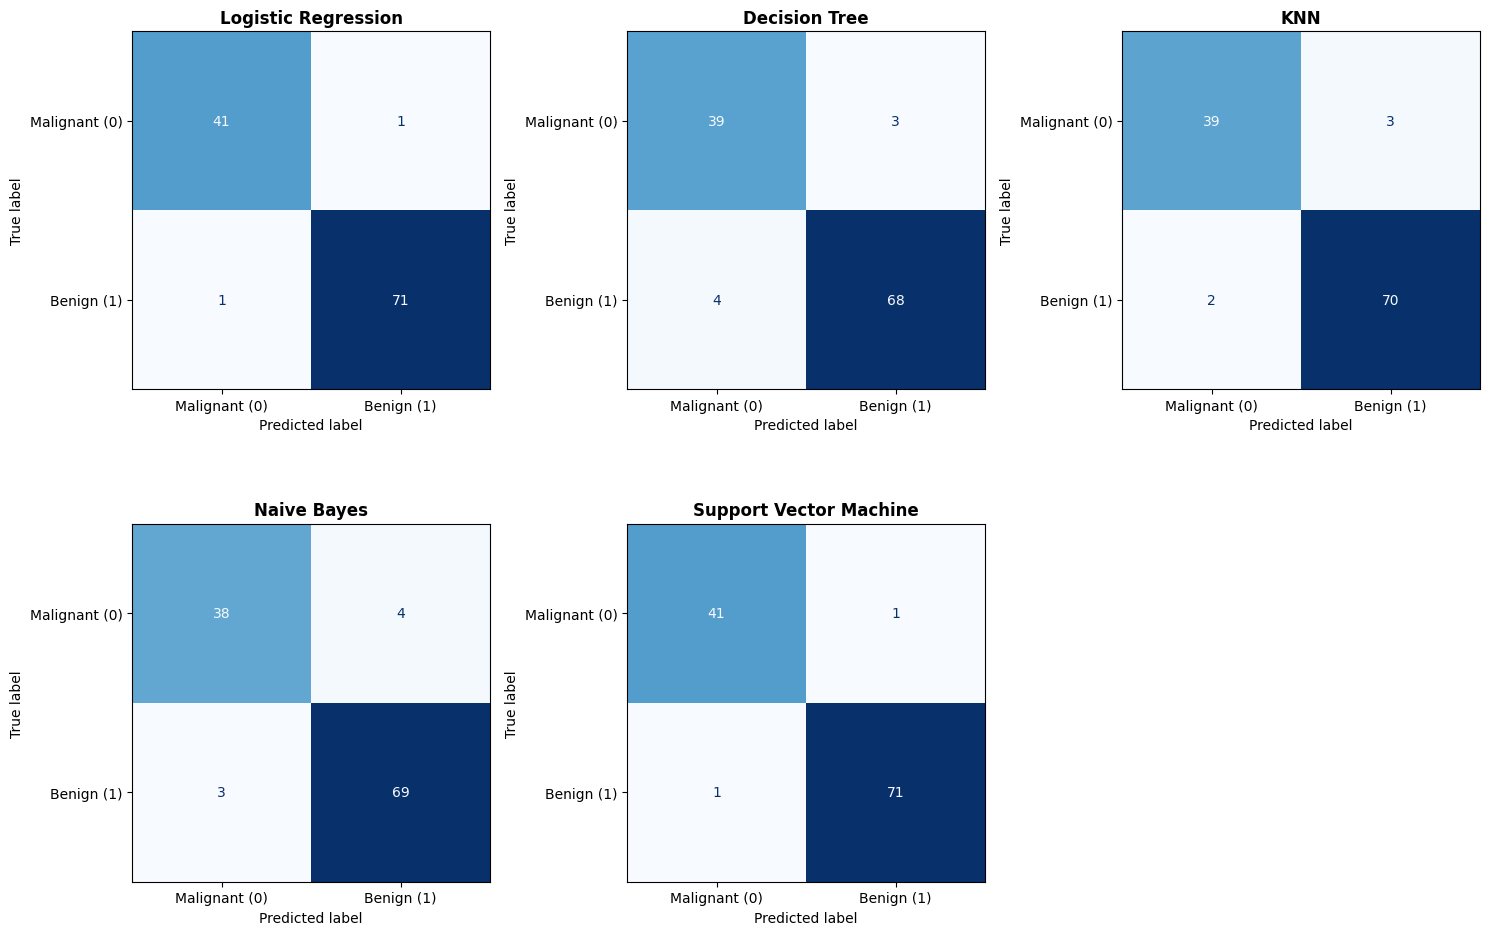

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, (name, clf) in enumerate(models.items()):
    if name in ["Logistic Regression", "KNN", "Support Vector Machine"]:
        y_pred = clf.predict(X_test_scaled)
    else:
        y_pred = clf.predict(X_test)
        
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Malignant (0)", "Benign (1)"])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(name, fontsize=12, fontweight='bold')

# Hide the unused 6th subplot
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()